# Data summary of my five flux towers

**Author:** Phoebe Wells

**Date:** November 18, 2026

In [ ]:
import os
import zipfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#os.chdir("/Users/phoebewells/Documents/datascience_env_monit")

In [ ]:
def read_hh(zip_file):
    with zipfile.ZipFile(zip_file) as z:
        hh_name = [n for n in z.namelist() if "FLUXMET_HH" in n][0]
        with z.open(hh_name) as f:
            hh = pd.read_csv(f, na_values=[-9999],
                         usecols=lambda c: c in keep,
                         dtype={"TIMESTAMP_START": str, "TIMESTAMP_END": str})

    hh["time"] = pd.to_datetime(hh["TIMESTAMP_START"], format="%Y%m%d%H%M")
    filename = Path(zip_file).name
    hh['site'] = filename.split("_")[1]
    return hh
    
all_data = []

for zip_file in Path("data/raw").glob("*.zip"):
    tower_data = read_hh(zip_file)
    all_data.append(tower_data)

all_towers = pd.concat(all_data, ignore_index=True)
all_towers.head()

,TIMESTAMP_START,TIMESTAMP_END,TA_F,SW_IN_F,VPD_F,P_F,NETRAD,G_F_MDS,LE_F_MDS,LE_F_MDS_QC,H_F_MDS,H_F_MDS_QC,NEE_VUT_REF,NEE_VUT_REF_QC,RECO_NT_VUT_REF,GPP_NT_VUT_REF,time,site
0,201101010000,201101010030,-0.107,0.0,0.264,0.028,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-01-01 00:00:00,DE-RuR
1,201101010030,201101010100,-0.097,0.0,0.261,0.028,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-01-01 00:30:00,DE-RuR
2,201101010100,201101010130,-0.087,0.0,0.258,0.040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-01-01 01:00:00,DE-RuR
3,201101010130,201101010200,-0.064,0.0,0.268,0.040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-01-01 01:30:00,DE-RuR
4,201101010200,201101010230,-0.042,0.0,0.278,0.049,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2011-01-01 02:00:00,DE-RuR


In [15]:
## Site overview (C1)

site_data = {
    "site_ID": ["CA-ARF", "US-CMW", "DE-RuR", "SE-Htm", "KR-Hnm"],
    "name": ["Attawapiskat River Fen", "Charleston Mesquite Woodland", "Rollesbroich", "Hyltemossa", "Haenam Farmland (HFK)"],
    "country": ["United States", "United States", "Germany", "Sweden", "South Korea"],
    "IGBP_class": ["WET", "DBF", "GRA", "ENF", "CRO"],
    "latitude": [52.7008, 31.6637, 50.621914, 56.09763, 34.5538],
    "longitude": [-83.955, -110.1777, 6.304126, 13.41897, 126.56992],
    "first_year": [2011, 2001, 2011, 2018, 2016],
    "last_year": [2024, 2021, 2025, 2026, 2019],
    "hub": ["AmeriFlux", "AmeriFlux", "ICOS", "ICOS", "ICOS"],
    "data_citation": ["Aaron Todd, Elyn Humphreys (2026), AmeriFlux FLUXNET-1F CA-ARF Attawapiskat River Fen, Ver. v1.3_r1 (2011-2024), AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/1902822", "Russell Scott (2026), AmeriFlux FLUXNET-1F US-CMW Charleston Mesquite Woodland, Ver. v1.3_r1 (2001-2021), AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/3028957", "Schmidt, M., Bagheri, S., Becker, N., Dolfus, D., Graf, A., Kettler, M., Kummer, S., Mattes, J. (2026). Fluxnet Archive Product from Rollesbroich, 2011–2025, FLUXNET, https://hdl.handle.net/11676/Vs7FI6NOiRl_VH7Wkclfl_3t", "Heliasz, M., Kljun, N., Biermann, T., Holst, J., Holst, T., Kornacher, P., Linderson, M.-L., Molder, M., Rinne, J., Rinne, J. (2026). Fluxnet Archive Product from Hyltemossa, 2018-01-01–2026-09-06, FLUXNET. https://hdl.handle.net/11676/ijcFWAyxq647kIP7fgVh7KkC", "Cho, J., Cho, S., Kang, M. (2025). Fluxnet Archive Product from Haenam Farmland (HFK), 2016–2019, FLUXNET. https://hdl.handle.net/11676/6juxi14AX0CYmbd3rABrd8Qg"]
}

site_overview = pd.DataFrame(site_data)
print(site_overview)

#map
import plotly.express as px

fig = px.scatter_geo(
    site_overview,
    lat="latitude",
    lon="longitude",
    hover_name="site_ID",
    text="site_ID",
    title="Locations of Five Flux Towers",
    projection="natural earth"
)

fig.update_traces(
    marker=dict(size=10, color="red")
)

fig.show()

  site_ID                          name        country IGBP_class   latitude  \
0  CA-ARF        Attawapiskat River Fen  United States        WET  52.700800   
1  US-CMW  Charleston Mesquite Woodland  United States        DBF  31.663700   
2  DE-RuR                  Rollesbroich        Germany        GRA  50.621914   
3  SE-Htm                    Hyltemossa         Sweden        ENF  56.097630   
4  KR-Hnm         Haenam Farmland (HFK)    South Korea        CRO  34.553800   

    longitude  first_year  last_year        hub  \
0  -83.955000        2011       2024  AmeriFlux   
1 -110.177700        2001       2021  AmeriFlux   
2    6.304126        2011       2025       ICOS   
3   13.418970        2018       2026       ICOS   
4  126.569920        2016       2019       ICOS   

                                       data_citation  
0  Aaron Todd, Elyn Humphreys (2026), AmeriFlux F...  
1  Russell Scott (2026), AmeriFlux FLUXNET-1F US-...  
2  Schmidt, M., Bagheri, S., Becker, N., Dolfus

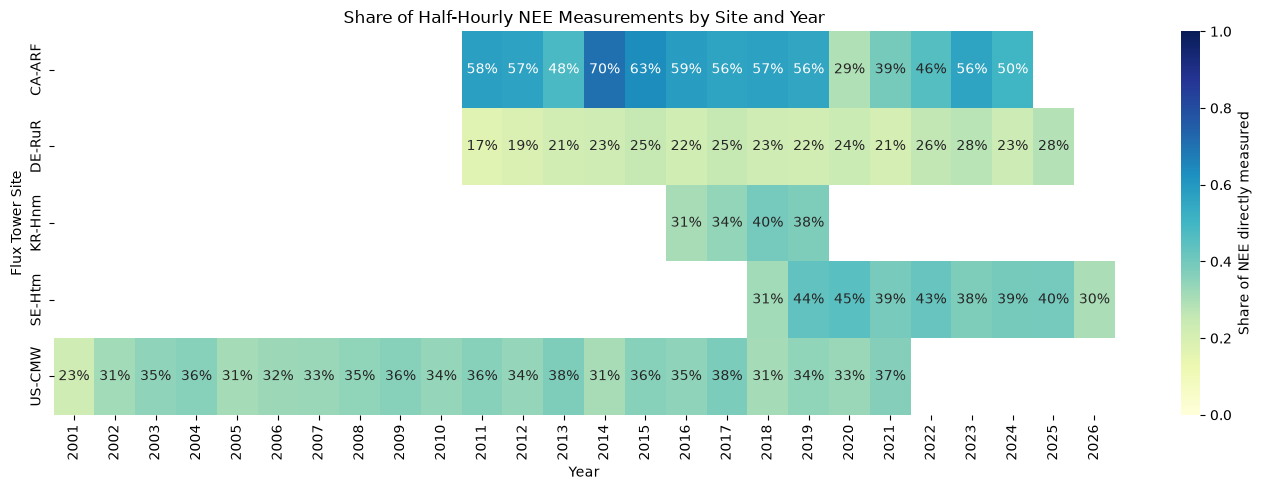

In [18]:
## Data Coverage (C2)
# Extract year from timestamp
all_towers["year"] = all_towers["time"].dt.year

# Create Boolean column: True if NEE was directly measured
all_towers["NEE_measured"] = all_towers["NEE_VUT_REF_QC"] == 0

# Calculate share measured for each site and year
quality = all_towers.groupby(["site", "year"])["NEE_measured"].mean().unstack()

#Create heatmap
plt.figure(figsize=(14, 5))
sns.heatmap(
    quality,
    annot=True,
    fmt=".0%",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Share of NEE directly measured"}
)
plt.title("Share of Half-Hourly NEE Measurements by Site and Year")
plt.xlabel("Year")
plt.ylabel("Flux Tower Site")
plt.tight_layout()
plt.show()


CA-ARF overall has the best data, mostly sitting above 50%, especially 2014 and 2015 (70% and 63% respectively). The rest of the sites hover in the 30% range with DE-RuR consistently in the 20% range.

In [ ]:
# Summary Statistics (C3)
units = {
    "TA_F": "°C",
    "SW_IN_F": "W m⁻²",
    "VPD_F": "hPa",
    "P_F": "mm",
    "NEE_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "GPP_NT_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "RECO_NT_VUT_REF": "µmol CO₂ m⁻² s⁻¹",
    "H_F_MDS": "W m⁻²",
    "LE_F_MDS": "W m⁻²"
}

summary = pd.DataFrame(index=all_towers["site"].unique())

for variable, unit in units.items():

    grouped = all_towers.groupby("site")[variable]

    summary[f"{variable} mean ({unit})"] = grouped.mean()
    summary[f"{variable} min ({unit})"] = grouped.min()
    summary[f"{variable} max ({unit})"] = grouped.max()
    summary[f"{variable} missing (%)"] = grouped.apply(
        lambda x: x.isna().mean() * 100
    )

# Extract year
all_towers["year"] = all_towers["time"].dt.year

# Calculate annual precipitation totals
annual_precip = all_towers.groupby(
    ["site", "year"]
)["P_F"].sum(min_count=1)

# Calculate mean annual precipitation per site
mean_annual_precip = annual_precip.groupby("site").mean()

# Replace the ordinary mean column
summary["P_F mean annual sum (mm/year)"] = mean_annual_precip
summary = summary.drop(columns=["P_F mean (mm)"])
summary

,TA_F mean (°C),TA_F min (°C),TA_F max (°C),TA_F missing (%),SW_IN_F mean (W m⁻²),SW_IN_F min (W m⁻²),SW_IN_F max (W m⁻²),SW_IN_F missing (%),VPD_F mean (hPa),VPD_F min (hPa),...,RECO_NT_VUT_REF missing (%),H_F_MDS mean (W m⁻²),H_F_MDS min (W m⁻²),H_F_MDS max (W m⁻²),H_F_MDS missing (%),LE_F_MDS mean (W m⁻²),LE_F_MDS min (W m⁻²),LE_F_MDS max (W m⁻²),LE_F_MDS missing (%),P_F mean annual sum (mm/year)
DE-RuR,8.645940,-17.039,34.950,0.000000,132.537653,0.0,1223.77,0.000000,2.856372,0.0,...,2.123259,2.297776,-259.356,386.903,2.108429,42.163392,-212.4420,531.416,2.108429,897.839600
KR-Hnm,14.383118,-9.748,35.474,0.000000,169.786018,0.0,1096.00,0.000000,5.353594,0.0,...,0.805670,21.073358,-299.996,981.778,0.792836,60.597570,-299.1920,995.151,0.794262,4567.605000
CA-ARF,-0.694601,-40.261,34.850,0.000000,141.867575,0.0,1058.00,0.000000,3.238906,0.0,...,7.373550,19.949418,-111.698,492.866,8.338222,24.004399,-46.7606,427.763,8.905700,491.710857
US-CMW,16.946769,-16.230,41.870,0.000000,234.584241,0.0,1262.25,0.000000,14.291070,0.0,...,1.381465,63.900914,-199.624,777.673,1.373859,51.999018,-49.9717,880.741,1.373859,263.346048
SE-Htm,8.734873,-15.840,34.490,3.985397,125.217085,0.0,1096.97,3.985397,2.610935,0.0,...,6.770358,17.421377,-282.480,658.710,6.237958,32.648242,-75.4300,605.800,6.237958,785.652111


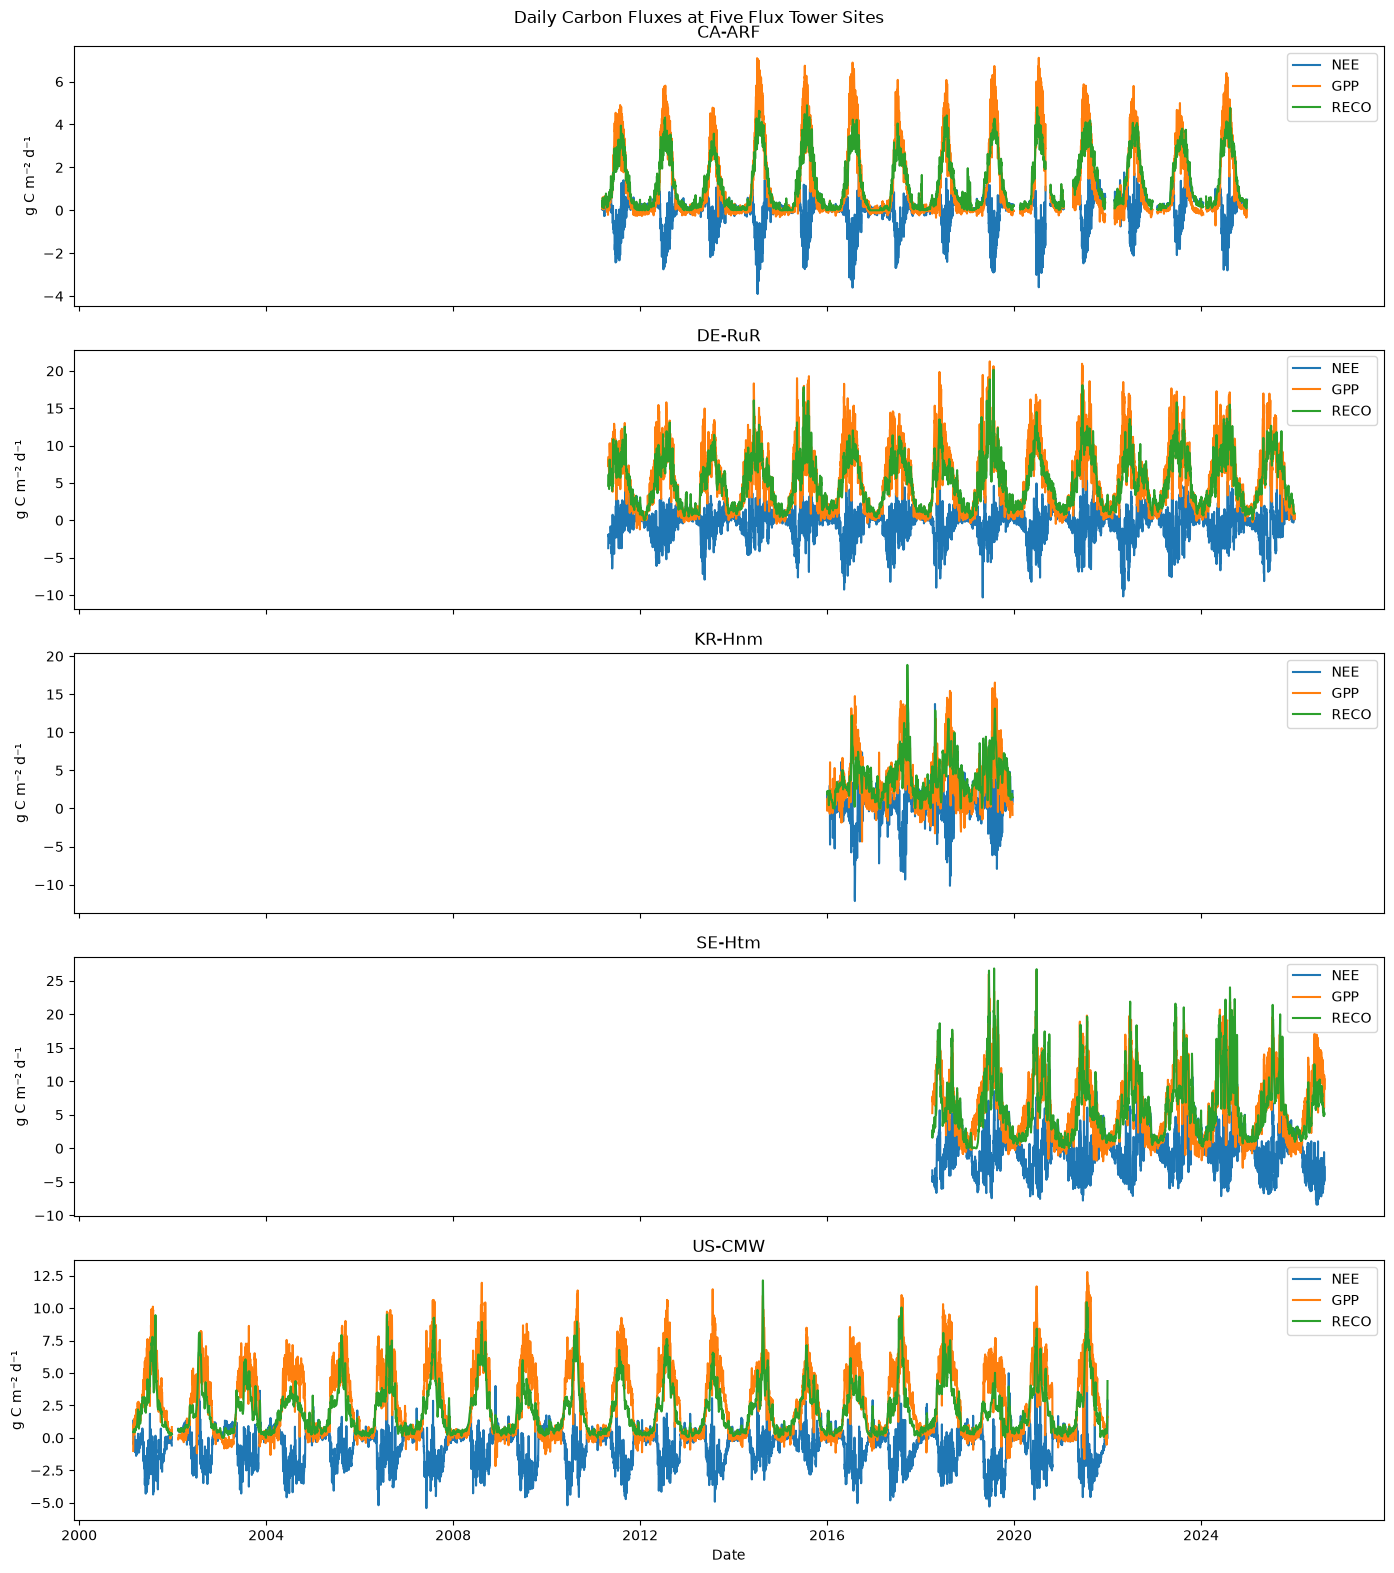

In [24]:
#Time Series (C4)
flux_vars = ["NEE_VUT_REF", "GPP_NT_VUT_REF", "RECO_NT_VUT_REF"]

#agreegate half-hourly data to daily means
daily = (
    all_towers
    .set_index("time")
    .groupby("site")[flux_vars]
    .resample("D")
    .mean()
    .reset_index()
)

#convert into carbon units
for var in flux_vars:
    daily[var] = daily[var] * 1.0378

#plot daily time series
sites = daily["site"].unique()

fig, axes = plt.subplots(
    nrows=len(sites),
    ncols=1,
    figsize=(14, 16),
    sharex=True
)

for ax, site in zip(axes, sites):

    site_data = daily[daily["site"] == site]

    ax.plot(site_data["time"], site_data["NEE_VUT_REF"], label="NEE")
    ax.plot(site_data["time"], site_data["GPP_NT_VUT_REF"], label="GPP")
    ax.plot(site_data["time"], site_data["RECO_NT_VUT_REF"], label="RECO")

    ax.set_title(site)
    ax.set_ylabel("g C m⁻² d⁻¹")
    ax.legend()

axes[-1].set_xlabel("Date")

fig.suptitle("Daily Carbon Fluxes at Five Flux Tower Sites")
plt.tight_layout()
plt.show()



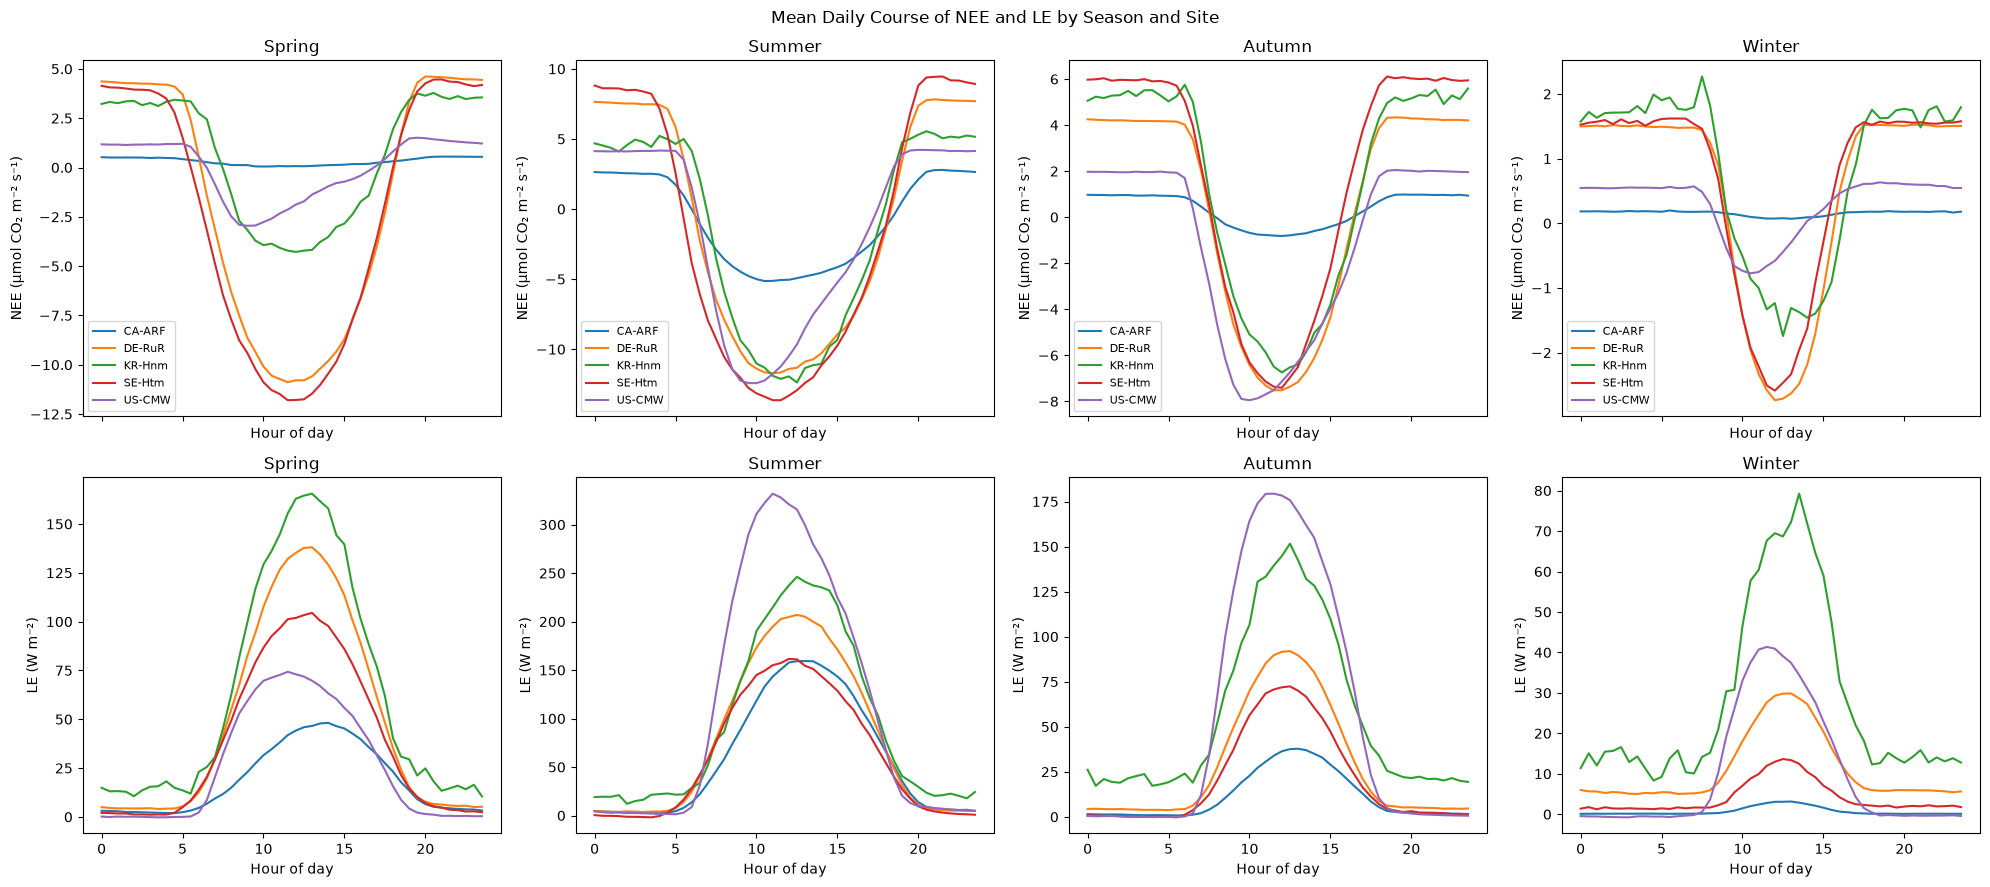

In [ ]:
#Diurnal cycles (C5)
merge latitude to half-hourly data
all_towers = all_towers.merge(
    site_overview[["site_ID", "latitude"]],
    left_on="site",
    right_on="site_ID"
)

#extract month and hour
all_towers["month"] = all_towers["time"].dt.month
all_towers["hour"] = (
    all_towers["time"].dt.hour
    + all_towers["time"].dt.minute / 60
)

#assign seasons
def get_season(month, latitude):
    if latitude >= 0:  # Northern Hemisphere
        if month in [12, 1, 2]:
            return "Winter"
        elif month in [3, 4, 5]:
            return "Spring"
        elif month in [6, 7, 8]:
            return "Summer"
        else:
            return "Autumn"

    else:  # Southern Hemisphere
        if month in [12, 1, 2]:
            return "Summer"
        elif month in [3, 4, 5]:
            return "Autumn"
        elif month in [6, 7, 8]:
            return "Winter"
        else:
            return "Spring"

#fix latitude column
all_towers["latitude"] = all_towers["latitude_y"]
all_towers = all_towers.drop(columns=["latitude_x", "latitude_y"])
#fix site id column
# Fix site_ID column
all_towers["site_ID"] = all_towers["site_ID_y"]
all_towers = all_towers.drop(columns=["site_ID_x", "site_ID_y"])

all_towers["season"] = all_towers.apply(
    lambda row: get_season(row["month"], row["latitude"]),
    axis=1
)

#mean NEE and LE for each combo
daily_course = (
    all_towers
    .groupby(["site", "season", "hour"])[["NEE_VUT_REF", "LE_F_MDS"]]
    .mean()
    .reset_index()
)

import matplotlib.pyplot as plt

seasons = ["Spring", "Summer", "Autumn", "Winter"]
sites = daily_course["site"].unique()

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True)

for i, season in enumerate(seasons):

    season_data = daily_course[daily_course["season"] == season]

    # NEE (top row)
    for site in sites:
        site_data = season_data[season_data["site"] == site]
        axes[0, i].plot(
            site_data["hour"],
            site_data["NEE_VUT_REF"],
            label=site
        )

    axes[0, i].set_title(season)
    axes[0, i].set_ylabel("NEE (µmol CO₂ m⁻² s⁻¹)")
    axes[0, i].set_xlabel("Hour of day")
    axes[0, i].legend(fontsize=8)

    # LE (bottom row)
    for site in sites:
        site_data = season_data[season_data["site"] == site]
        axes[1, i].plot(
            site_data["hour"],
            site_data["LE_F_MDS"],
            label=site
        )

    axes[1, i].set_title(season)
    axes[1, i].set_ylabel("LE (W m⁻²)")
    axes[1, i].set_xlabel("Hour of day")

fig.suptitle("Mean Daily Course of NEE and LE by Season and Site")
plt.tight_layout()
plt.show()


Seasons were assigned based on whether the latitude placed the site in the northern or southern hemisphere. December-February = winter in norther hemishphere and summer in southern hemisphere.

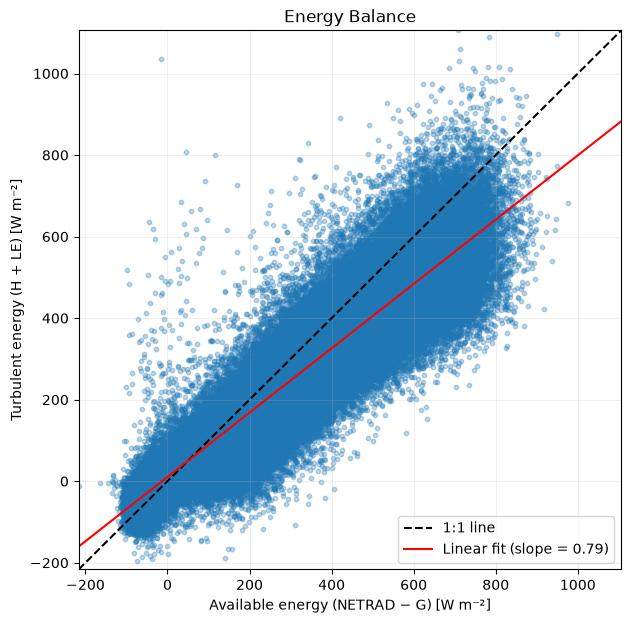

Slope: 0.789
Intercept: 10.497


In [45]:
#C6
#check towers
all_towers.groupby("site")[["NETRAD", "G_F_MDS"]].count()
#US-CMW has plenty
#filter
site_data = all_towers[all_towers["site"] == "US-CMW"].copy()

energy = site_data[
    (site_data["H_F_MDS_QC"] == 0) &
    (site_data["LE_F_MDS_QC"] == 0)
].dropna(subset=["NETRAD", "G_F_MDS", "H_F_MDS", "LE_F_MDS"])

#calculate energy components
energy["available_energy"] = energy["NETRAD"] - energy["G_F_MDS"]

energy["turbulent_energy"] = energy["H_F_MDS"] + energy["LE_F_MDS"]

#plot
x = energy["available_energy"]
y = energy["turbulent_energy"]

# Fit a straight line
slope, intercept = np.polyfit(x, y, 1)

# Create scatter plot
plt.figure(figsize=(7, 7))
plt.scatter(x, y, alpha=0.3, s=10)

# 1:1 line
limits = [
    min(x.min(), y.min()),
    max(x.max(), y.max())
]
plt.plot(limits, limits, "k--", label="1:1 line")

# Linear regression line
plt.plot(
    limits,
    slope * np.array(limits) + intercept,
    "r-",
    label=f"Linear fit (slope = {slope:.2f})"
)

plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Available energy (NETRAD − G) [W m⁻²]")
plt.ylabel("Turbulent energy (H + LE) [W m⁻²]")
plt.title("Energy Balance")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Slope: {slope:.3f}")
print(f"Intercept: {intercept:.3f}")

In [50]:
#compare average annual carbon uptake
# Extract year
daily["year"] = daily["time"].dt.year

# Calculate annual NEE sum for each site
annual_nee = daily.groupby(["site", "year"])["NEE_VUT_REF"].sum()

annual_nee

mean_annual_nee = annual_nee.groupby("site").mean()

print(mean_annual_nee.sort_values())

#compare seasonal cycles
#outputs seasonal ranges
seasonal_nee = all_towers.groupby(
    ["site", "season"]
)["NEE_VUT_REF"].mean().unstack()

seasonal_nee

seasonal_range = seasonal_nee.max(axis=1) - seasonal_nee.min(axis=1)

print(seasonal_range.sort_values(ascending=False))

#gaps?
gap_filled = all_towers.groupby("site")["NEE_VUT_REF_QC"].apply(
    lambda x: (x > 0).mean() * 100
)

print(gap_filled)

site
US-CMW   -243.881699
DE-RuR   -164.257477
SE-Htm   -156.861271
CA-ARF    -10.580591
KR-Hnm    133.566145
Name: NEE_VUT_REF, dtype: float64
site
SE-Htm    4.237889
KR-Hnm    2.818375
DE-RuR    2.272769
US-CMW    1.850548
CA-ARF    1.194985
dtype: float64
site
CA-ARF    39.407346
DE-RuR    74.760829
KR-Hnm    63.655031
SE-Htm    54.557727
US-CMW    64.814211
Name: NEE_VUT_REF_QC, dtype: float64


The annual average of -243.88 NEE shows that US-CMW takes up the most carbon per year. To compare seasonal cycles the range of the highest and lowest seasonal mean was calculated. This showed that SE-Htm has the largest seasonal cycle with a range of 4.23 NEE. Gaps in the data were found with the QC column, showing the percentage of the data that was flagged in the QC column. This shows a range from ~40-75% gap filled data depending on the site. The tower that surprised me the most was CA-ARF, as the NEE stays close to zero in the winter and spring throughout the day while the rest follow similar patterns. This could be do to lower solar radiation or cooler temperatures during those months.